In [1]:
import datetime as dt  
from py_eddy_tracker.dataset.grid import RegularGridDataset
from py_eddy_tracker.featured_tracking.area_tracker import AreaTracker
from py_eddy_tracker.gui import GUI
from py_eddy_tracker.tracking import Correspondances
from py_eddy_tracker.observations.tracking import TrackEddiesObservations

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy.feature as cfeature
import numpy as np
from numba import njit
import glob
import os
import sys
from netCDF4 import Dataset
from netCDF4 import num2date
from time import ctime
import seaborn as sns
import pandas as pd
import datetime
from tqdm import notebook
import tqdm

In [2]:
@njit(cache=True)
def sum_profile(x_new, y, out):
    """Will sum all interpolated given array"""
    out += np.interp(x_new, np.linspace(0, 1, y.size), y)
    
class MyObs(TrackEddiesObservations):
    def eddy_norm_lifetime(self, name, nb, factor=1):
        """
        :param str,array name: Array or field name
        :param int nb: size of output array
        """
        y = self.parse_varname(name)
        x = np.linspace(0, 1, nb)
        out = np.zeros(nb, dtype=y.dtype)
        nb_track = 0
        for i, b0, b1 in self.iter_on("track"):
            y_ = y[i]
            size_ = y_.size
            if size_ == 0:
                continue
            sum_profile(x, y_, out)
            nb_track += 1
        return x, out / nb_track * factor
def cftime2pdtime(cf):
    return pd.to_datetime(datetime.datetime(cf.year,cf.month,cf.day,cf.hour))

kw = dict(include_vars=("speed_radius", "amplitude", "track"))
a = MyObs.load_file('tmp_AC.nc', **kw)
c = MyObs.load_file('tmp_CC.nc', **kw)

In [3]:
ds=Dataset('tmp_AC.nc')
for i in ds.variables.keys():
    print(i)

amplitude
cost_association
effective_area
effective_contour_height
effective_contour_latitude
effective_contour_longitude
effective_contour_shape_error
effective_radius
inner_contour_height
latitude
latitude_max
longitude
longitude_max
num_contours
num_point_e
num_point_s
observation_flag
observation_number
speed_area
speed_average
speed_contour_height
speed_contour_latitude
speed_contour_longitude
speed_contour_shape_error
speed_radius
time
track
uavg_profile


In [4]:
def get_first_indices(arr):
    unique_values, indices = np.unique(arr, return_index=True)
    return indices
def get_last_indices(arr):
    reversed_arr = arr[::-1]
    unique_values, indices = np.unique(reversed_arr, return_index=True)
    return len(arr) - 1 - indices


In [5]:
a_x=Dataset('tmp_AC.nc').variables['longitude'][:]
a_y=Dataset('tmp_AC.nc').variables['latitude'][:]
a_first = get_first_indices(Dataset('tmp_AC.nc').variables['track'][:])
a_last = get_last_indices(Dataset('tmp_AC.nc').variables['track'][:])

In [6]:
c_x=Dataset('tmp_CC.nc').variables['longitude'][:]
c_y=Dataset('tmp_CC.nc').variables['latitude'][:]
c_first = get_first_indices(Dataset('tmp_CC.nc').variables['track'][:])
c_last = get_last_indices(Dataset('tmp_CC.nc').variables['track'][:])

In [7]:
g, axs = plt.subplots(2,2,figsize=(20,15),dpi=300,subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)})
ax = axs.flatten()[0]
ax.set_title('Anticyclonic start points')
sns.scatterplot(x=a_x[a_first], y=a_y[a_first], s=1, color=".15",ax=ax)
sns.histplot(x=a_x[a_first], y=a_y[a_first], bins=20, pthresh=.1, cmap="rocket",ax=ax)
sns.kdeplot(x=a_x[a_first], y=a_y[a_first], levels=10, color="g", linewidths=1,ax=ax)
ax.coastlines()
land = cfeature.NaturalEarthFeature('physical', 'land', '110m', edgecolor='face',
                                facecolor=cfeature.COLORS['land_alt1'])
ax.add_feature(land, zorder=0)
ax.set_aspect("equal")
ax.set_xlim(70, 100), ax.set_ylim(5, 25)

ax = axs.flatten()[1]
ax.set_title('Cyclonic start points')
sns.scatterplot(x=c_x[c_first], y=c_y[c_first], s=1, color=".15",ax=ax)
sns.histplot(x=c_x[c_first], y=c_y[c_first], bins=20, pthresh=.1, cmap="rocket",ax=ax)
sns.kdeplot(x=c_x[c_first], y=c_y[c_first], levels=10, color="g", linewidths=1,ax=ax)
ax.coastlines()
land = cfeature.NaturalEarthFeature('physical', 'land', '110m', edgecolor='face',
                                facecolor=cfeature.COLORS['land_alt1'])
ax.add_feature(land, zorder=0)
ax.set_aspect("equal")
ax.set_xlim(70, 100), ax.set_ylim(5, 25)

ax = axs.flatten()[2]
ax.set_title('Anticyclonic last points')
sns.scatterplot(x=a_x[a_last], y=a_y[a_last], s=1, color=".15",ax=ax)
sns.histplot(x=a_x[a_last], y=a_y[a_last], bins=20, pthresh=.1, cmap="rocket",ax=ax)
sns.kdeplot(x=a_x[a_last], y=a_y[a_last], levels=10, color="g", linewidths=1,ax=ax)
ax.coastlines()
land = cfeature.NaturalEarthFeature('physical', 'land', '110m', edgecolor='face',
                                facecolor=cfeature.COLORS['land_alt1'])
ax.add_feature(land, zorder=0)
ax.set_aspect("equal")
ax.set_xlim(70, 100), ax.set_ylim(5, 25)

ax = axs.flatten()[3]
ax.set_title('Cyclonic last points')
sns.scatterplot(x=c_x[c_last], y=c_y[c_last], s=1, color=".15",ax=ax)
sns.histplot(x=c_x[c_last], y=c_y[c_last], bins=20, pthresh=.1, cmap="rocket",ax=ax)
sns.kdeplot(x=c_x[c_last], y=c_y[c_last], levels=10, color="g", linewidths=1,ax=ax)
ax.coastlines()
land = cfeature.NaturalEarthFeature('physical', 'land', '110m', edgecolor='face',
                                facecolor=cfeature.COLORS['land_alt1'])
ax.add_feature(land, zorder=0)
ax.set_aspect("equal")
ax.set_xlim(70, 100), ax.set_ylim(5, 25)

c:\Users\53150\miniconda3\envs\eddy2\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\53150\miniconda3\envs\eddy2\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\53150\miniconda3\envs\eddy2\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\53150\miniconda3\envs\eddy2\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future ver

In [ ]:
acds=Dataset('tmp_AC.nc')
ac_time=pd.to_datetime(list(map(cftime2pdtime,num2date(acds.variables['time'][:],acds.variables['time'].units))))
ac_track=np.array(acds.variables['track'][:])


In [ ]:
ccds=Dataset('tmp_CC.nc')
cc_time=pd.to_datetime(list(map(cftime2pdtime,num2date(ccds.variables['time'][:],ccds.variables['time'].units))))
cc_track=np.array(ccds.variables['track'][:])

In [ ]:
list(range(1993,2023,5))

[1993, 1998, 2003, 2008, 2013, 2018]

  0%|          | 0/7 [00:00<?, ?it/s]

100%|██████████| 7/7 [02:27<00:00, 21.04s/it]


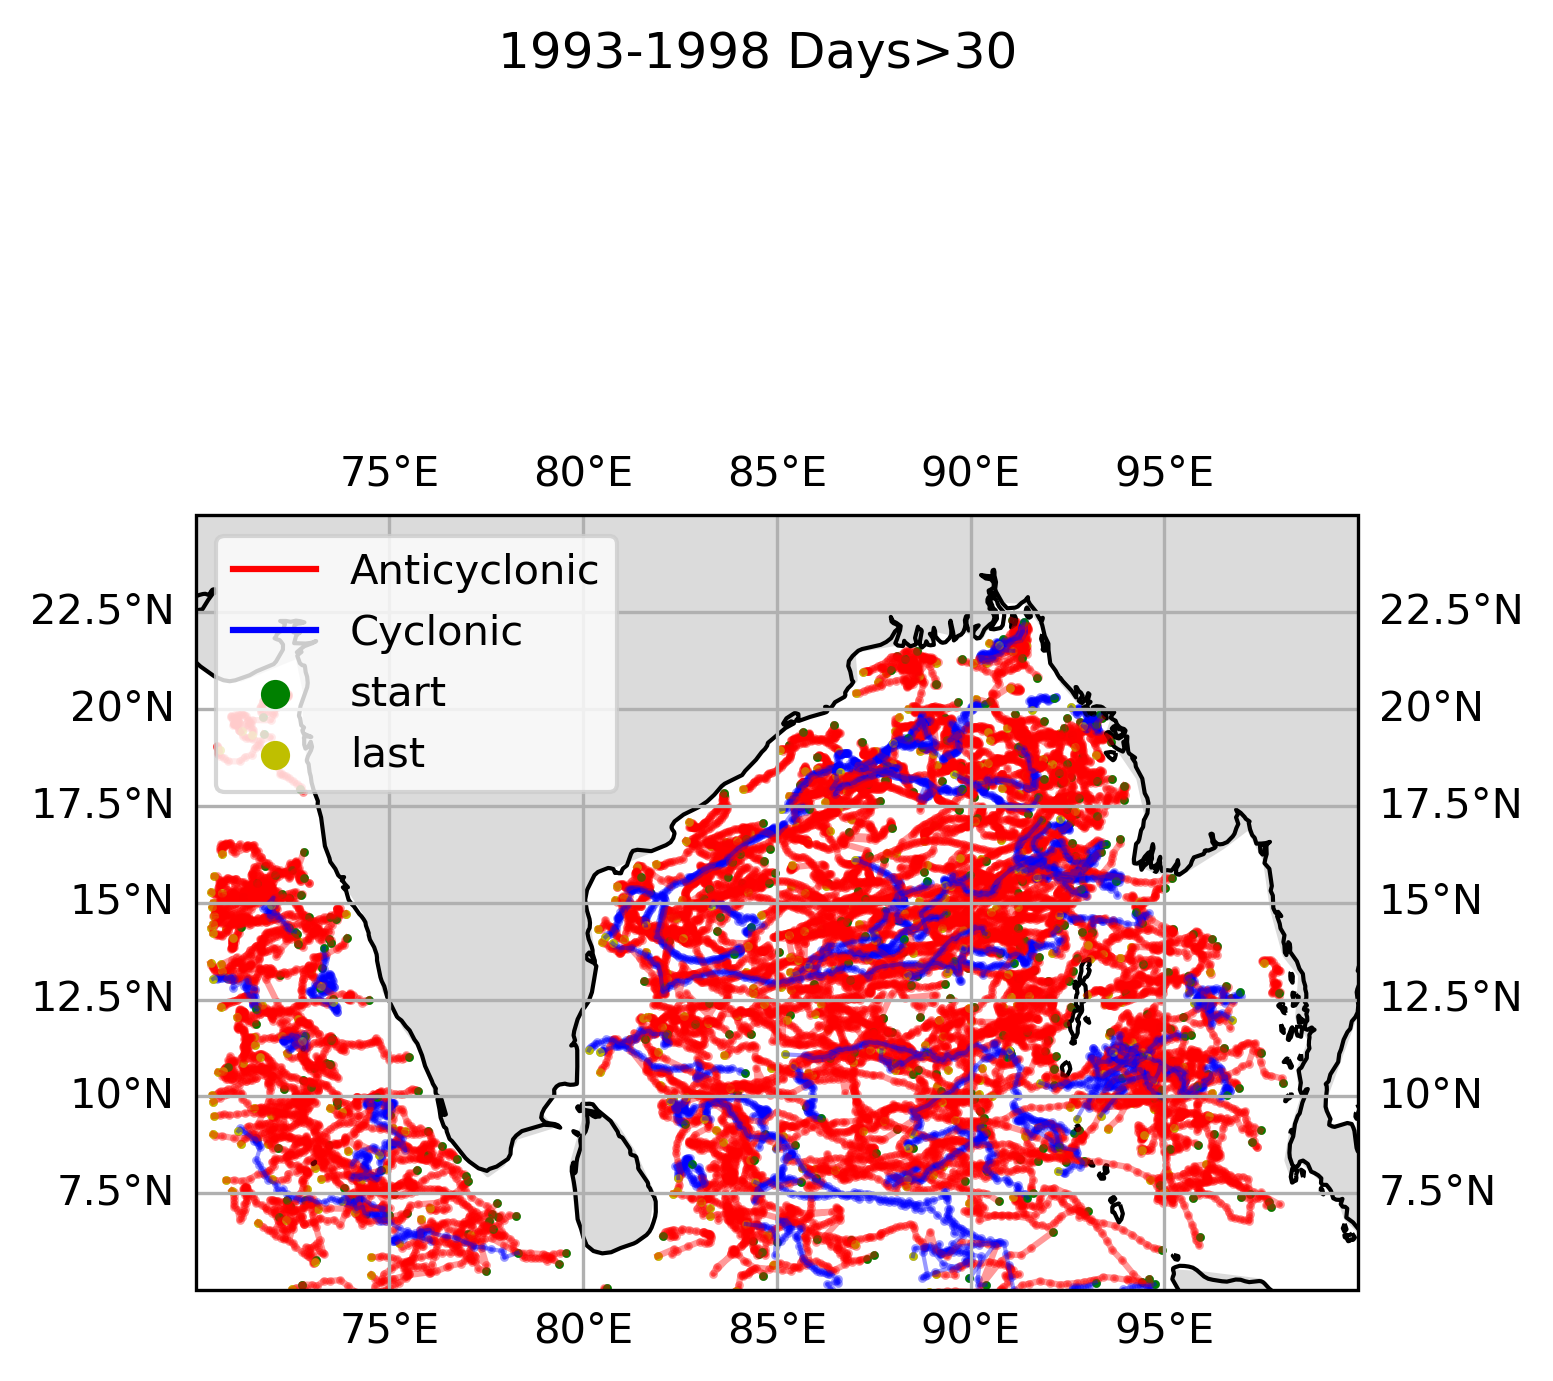

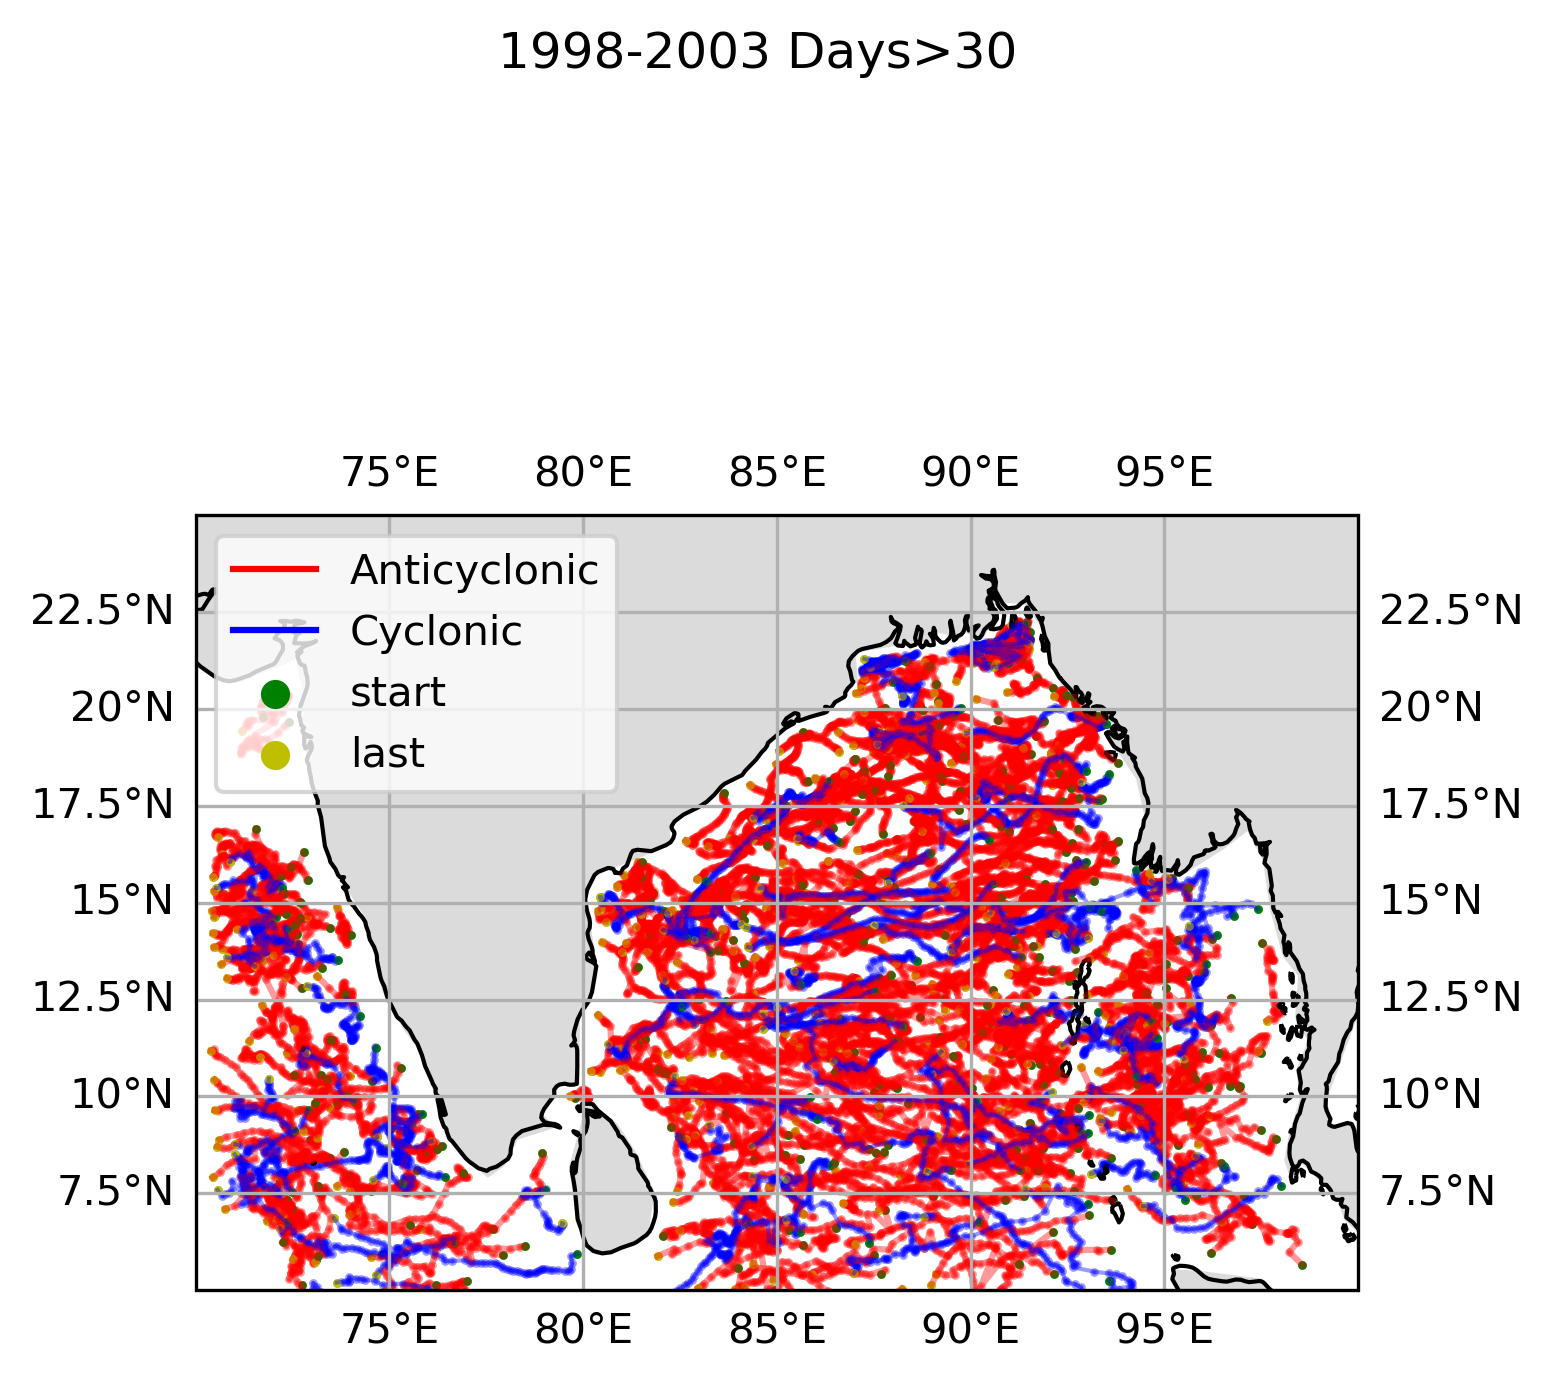

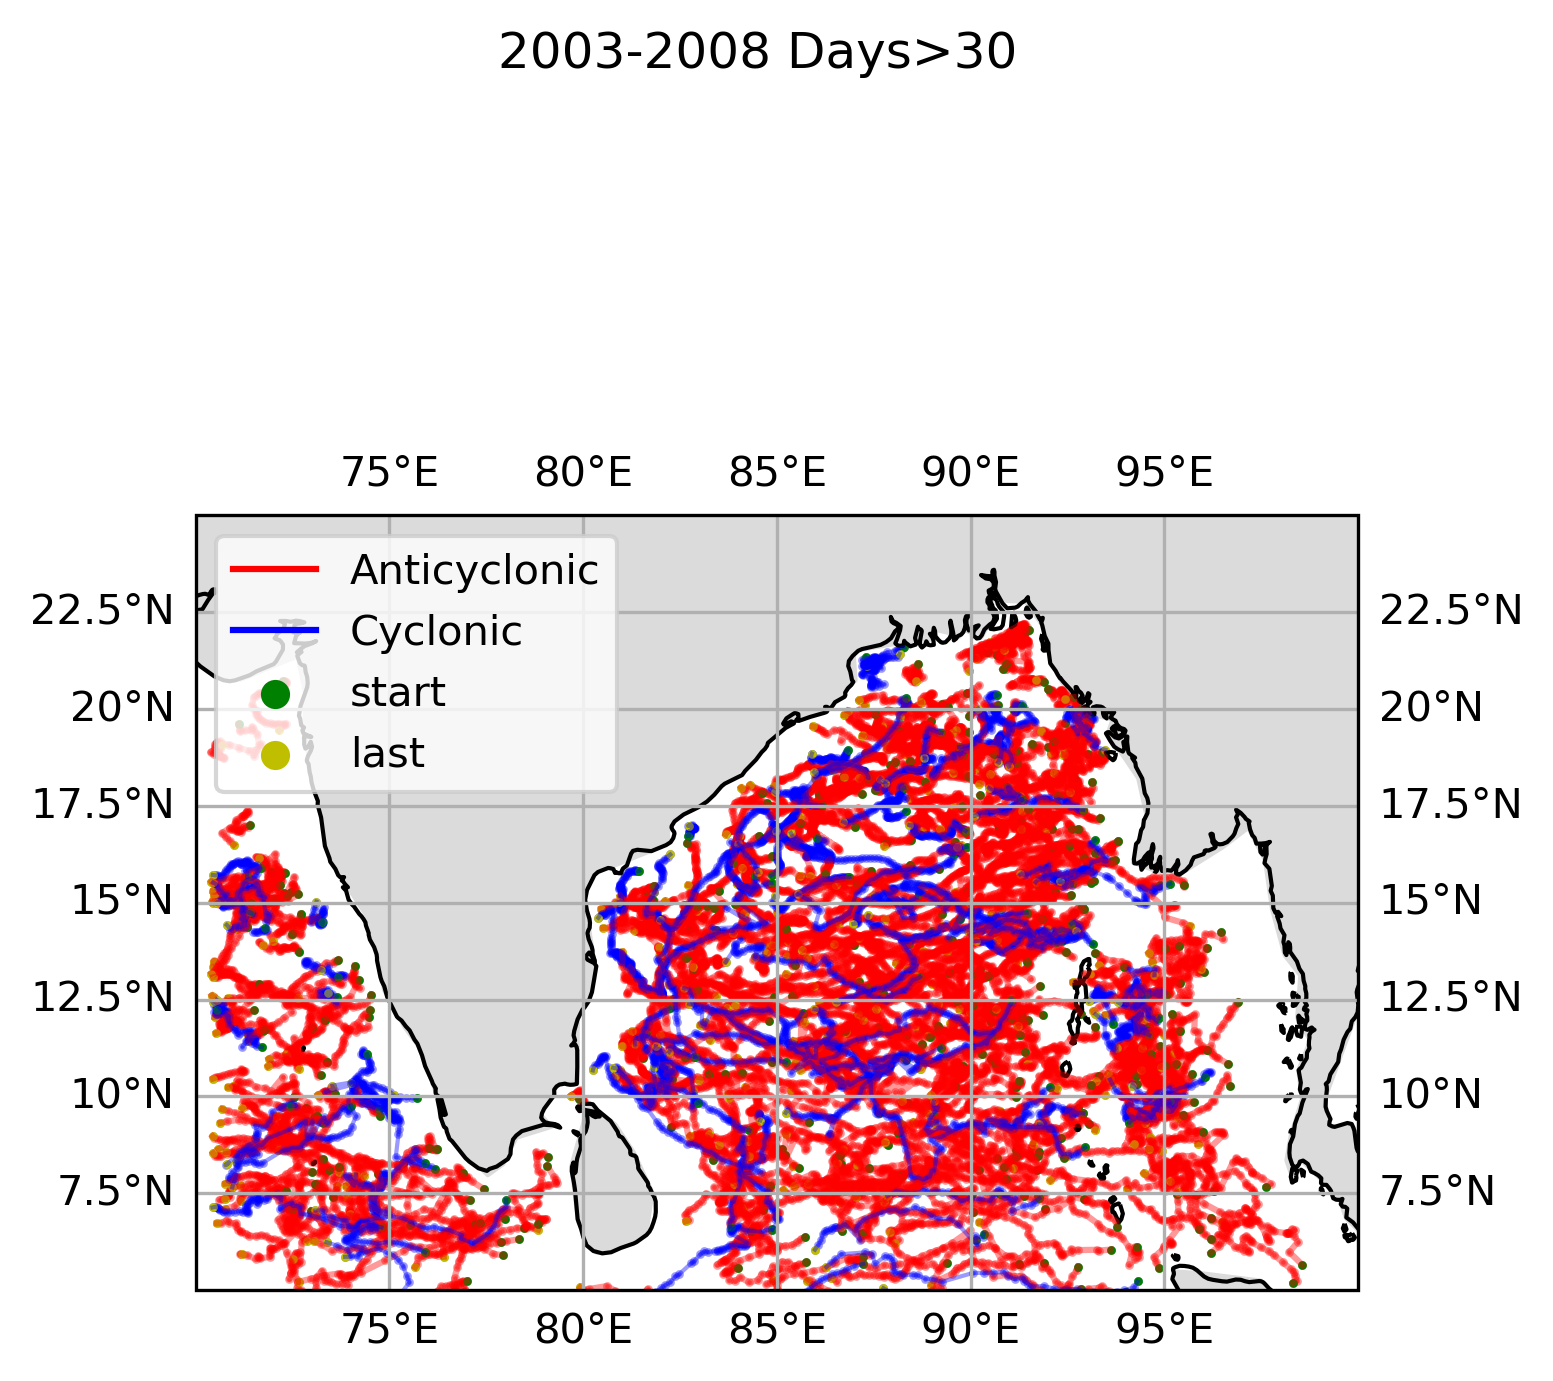

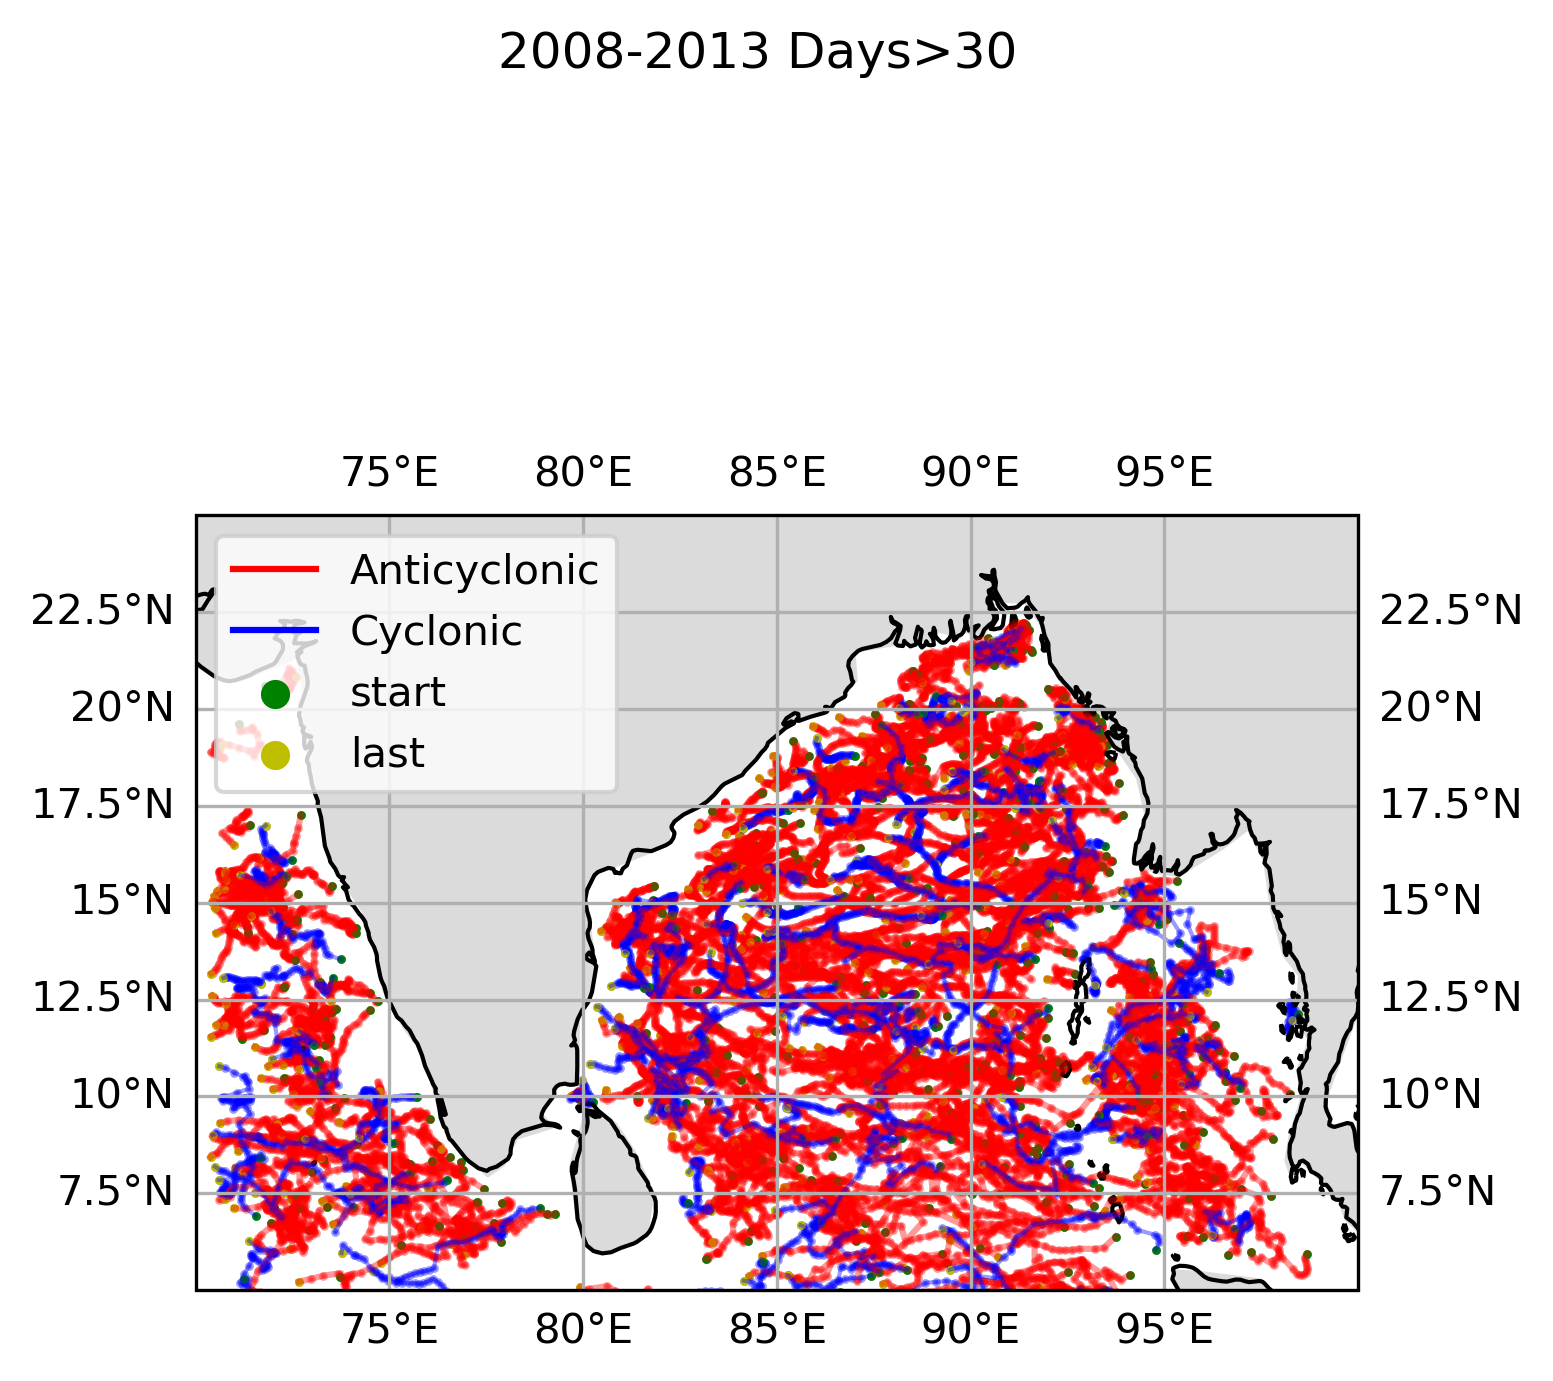

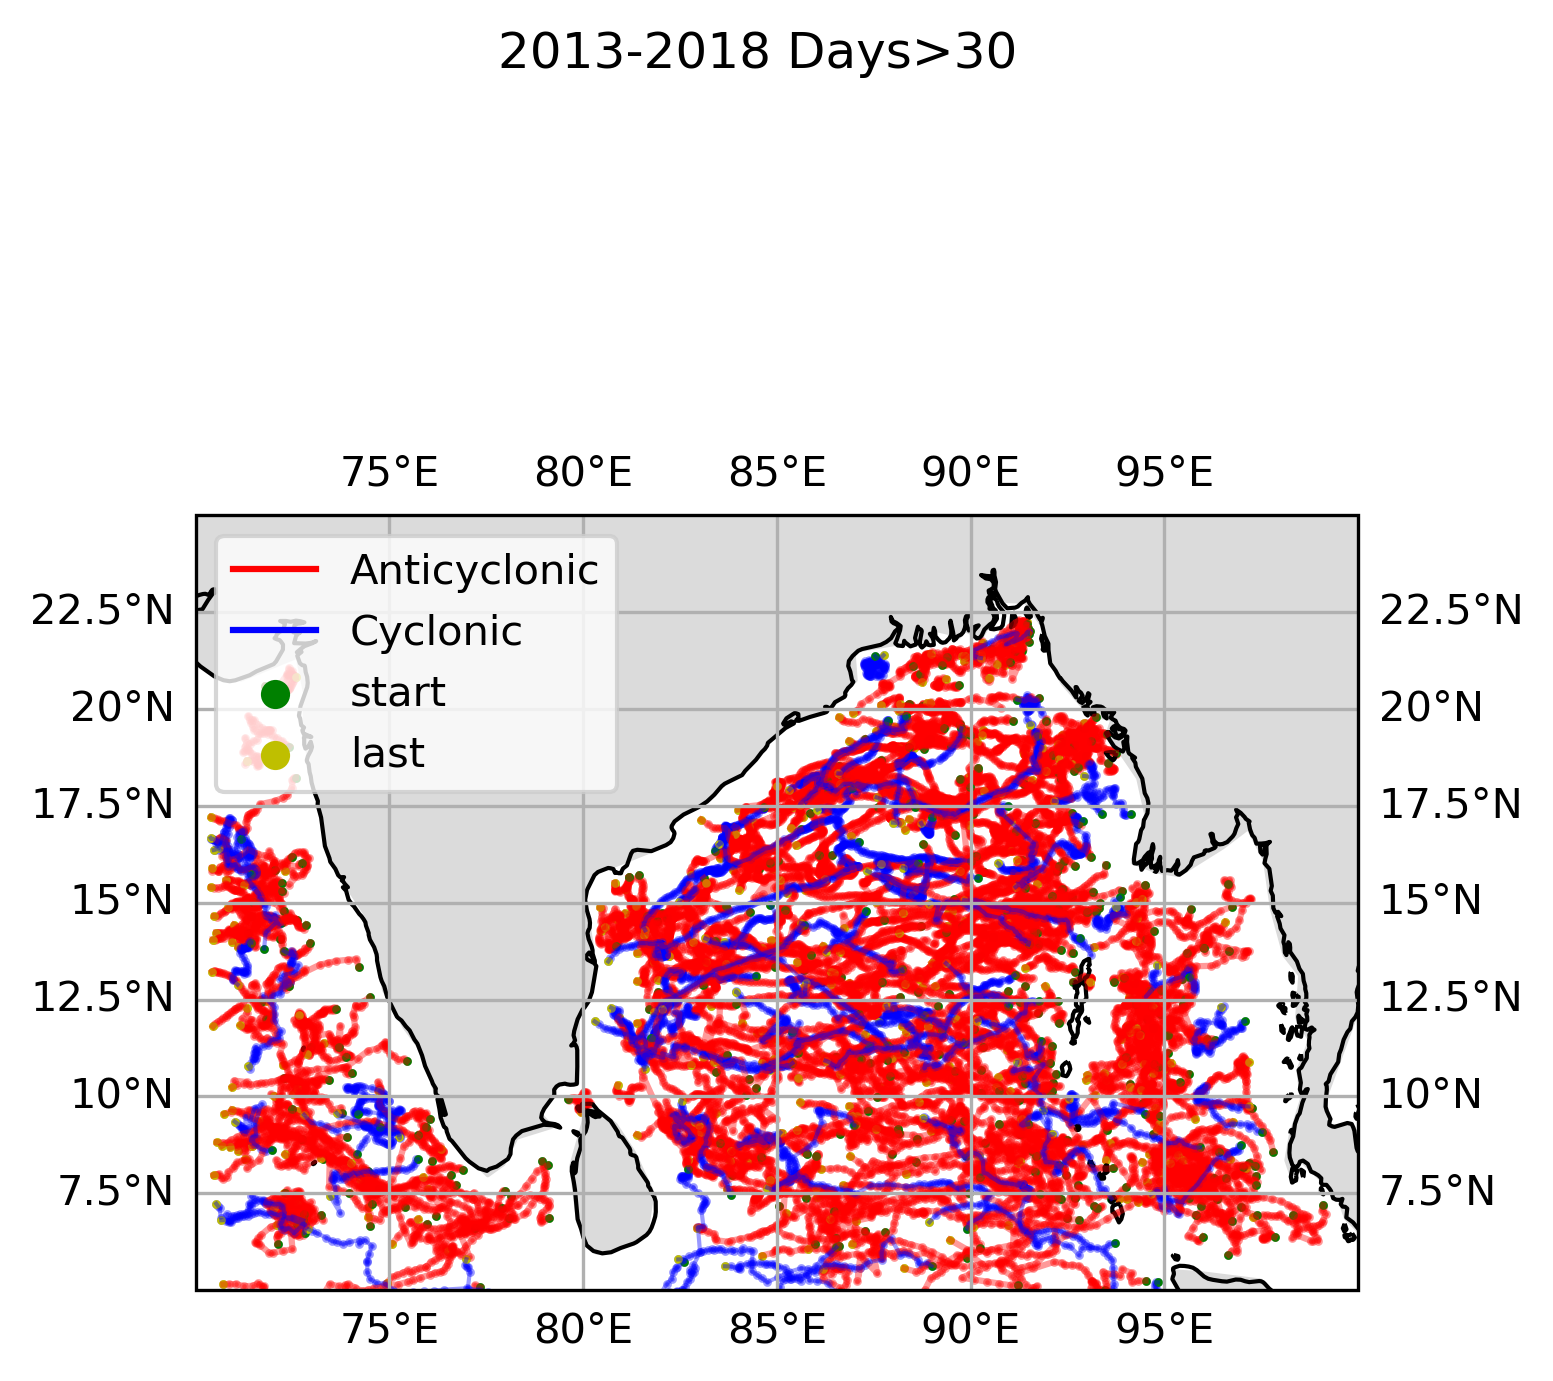

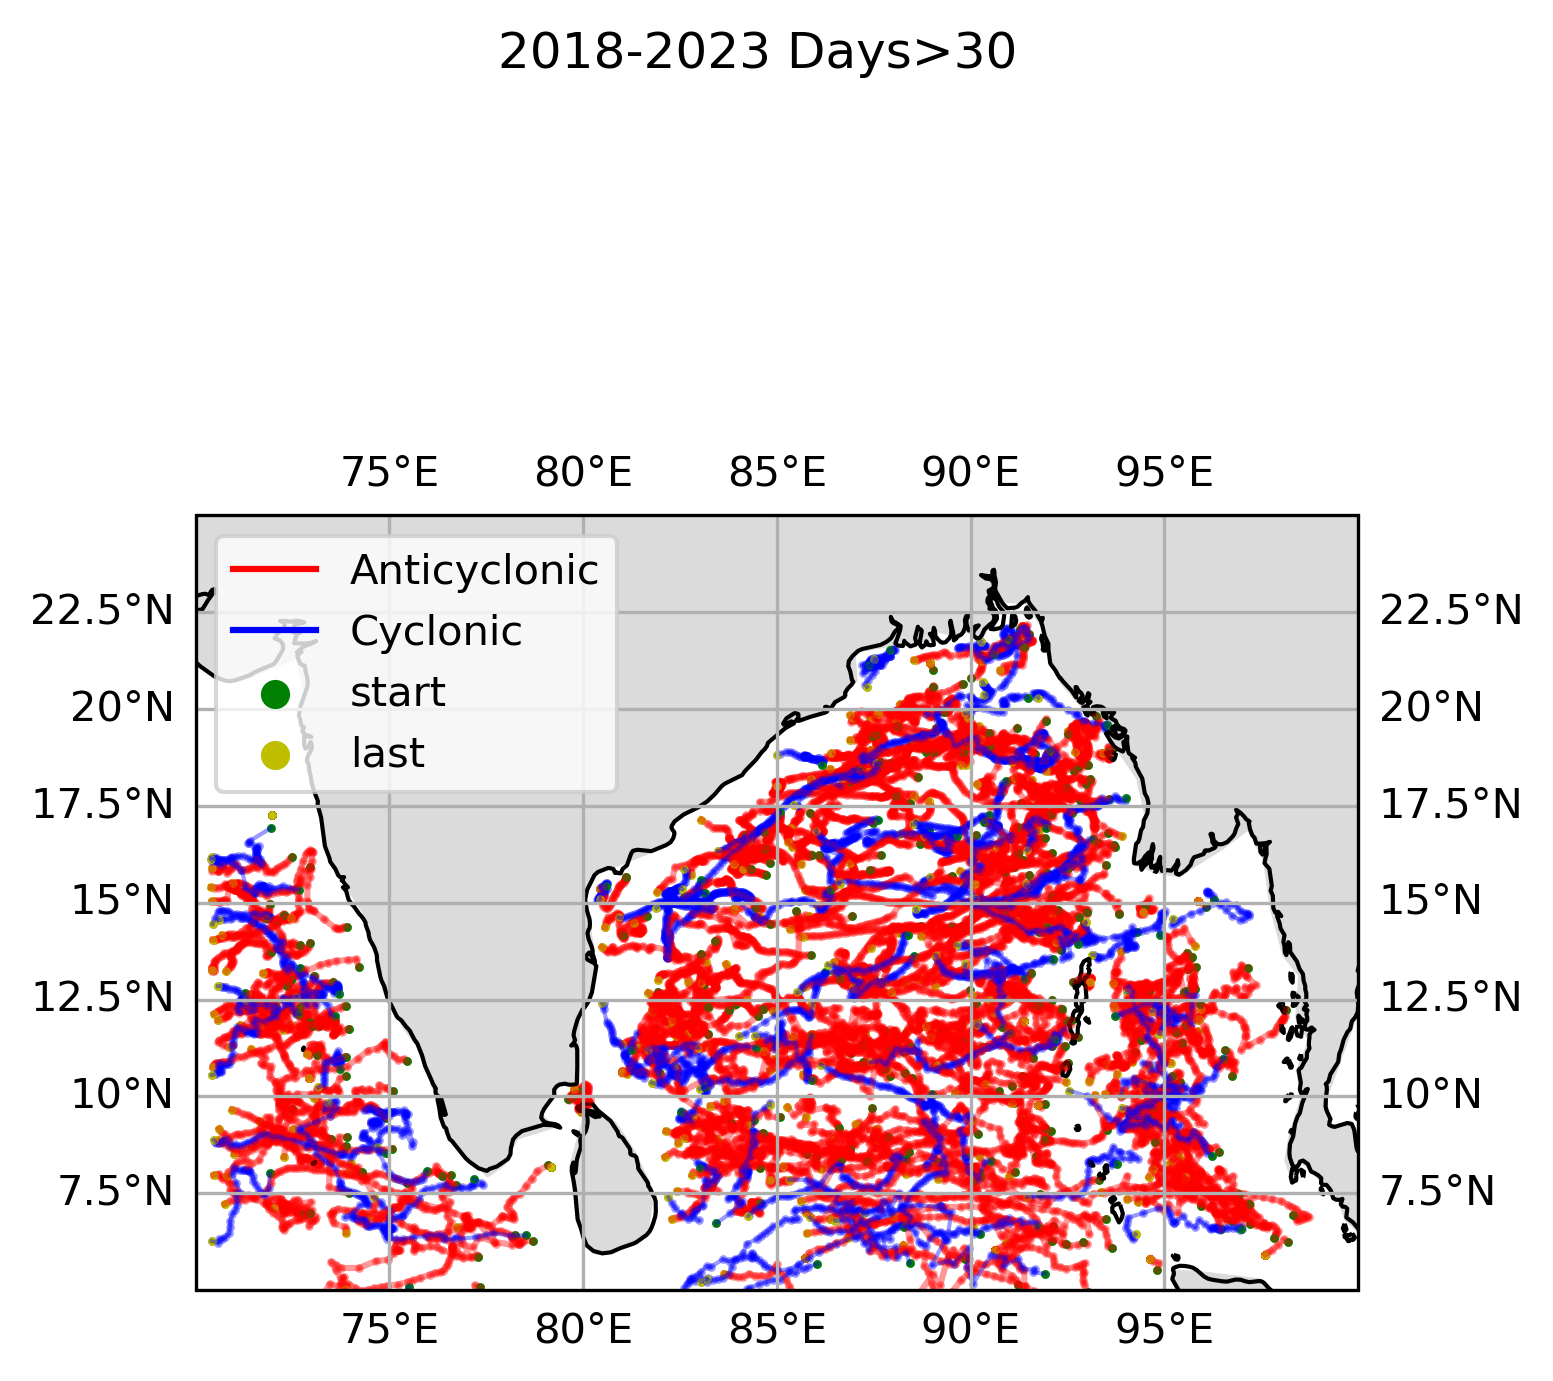

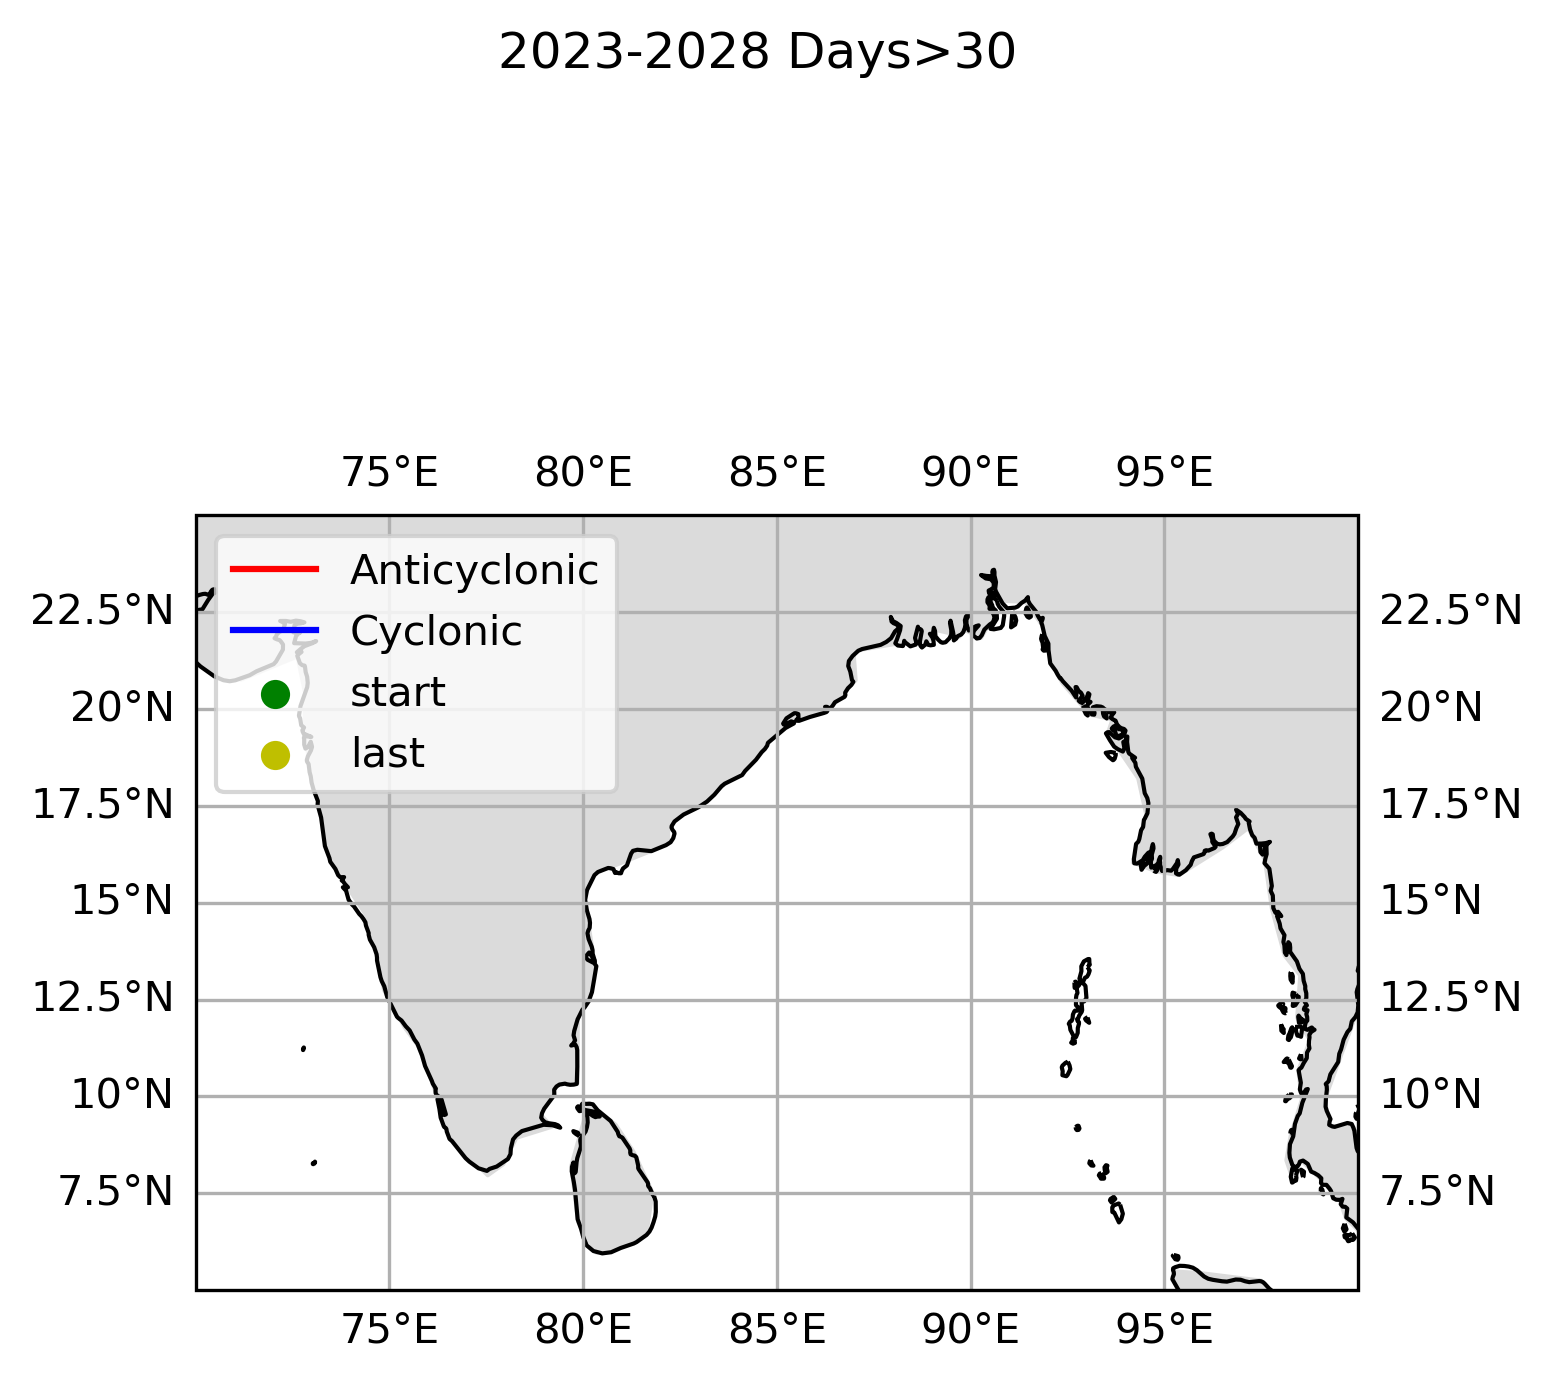

In [ ]:
for i in tqdm.tqdm(range(1993,2028,5)):
    g, axs = plt.subplots(1,1,figsize=(5,6),dpi=300,subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)})
    plt.suptitle(f'{i}-{i+5} Days>30')
    ax = axs
    ax.coastlines()
    land = cfeature.NaturalEarthFeature('physical', 'land', '110m', edgecolor='face',
                                    facecolor=cfeature.COLORS['land_alt1'])
    ax.add_feature(land, zorder=0)
    ax.set_aspect("equal")
    timeind=(ac_time.year>=i)&(ac_time.year<=i+5)
    trackind=np.unique(ac_track[timeind])
    plt.plot(0,0,'r',label='Anticyclonic')
    plt.plot(0,0,'b',label='Cyclonic')
    plt.scatter(0,0,c='g',label='start')
    plt.scatter(0,0,c='y',label='last')
    plt.legend(loc='upper left')
    for j in trackind:
        if np.sum(ac_track==j)<=30:
            continue
        plt.plot(a_x[ac_track==j],a_y[ac_track==j],c='r',linewidth=1.5,alpha=0.4)
        plt.scatter(a_x[ac_track==j],a_y[ac_track==j],c='r',s=1.2,alpha=0.4)
        plt.scatter(a_x[ac_track==j][0],a_y[ac_track==j][0],c='g',s=1.2)
        plt.scatter(a_x[ac_track==j][-1],a_y[ac_track==j][-1],c='y',s=1.2)
    timeind=cc_time.year==i
    trackind=np.unique(cc_track[timeind])
    for j in trackind:
        if np.sum(cc_track==j)<=30:
            continue
        plt.plot(c_x[cc_track==j],c_y[cc_track==j],c='b',linewidth=1,alpha=0.4)
        plt.scatter(c_x[cc_track==j],c_y[cc_track==j],c='b',s=1.2,alpha=0.4)
        plt.scatter(c_x[cc_track==j][0],c_y[cc_track==j][0],c='g',s=1.2)
        plt.scatter(c_x[cc_track==j][-1],c_y[cc_track==j][-1],c='y',s=1.2)
    ax.set_xlim(70,100)
    ax.set_ylim(5,25)
    ax.gridlines(draw_labels=True)
    plt.savefig(f'draws/track_{i}-{i+5}.png')

In [ ]:
np.sum(ac_track==j)

16

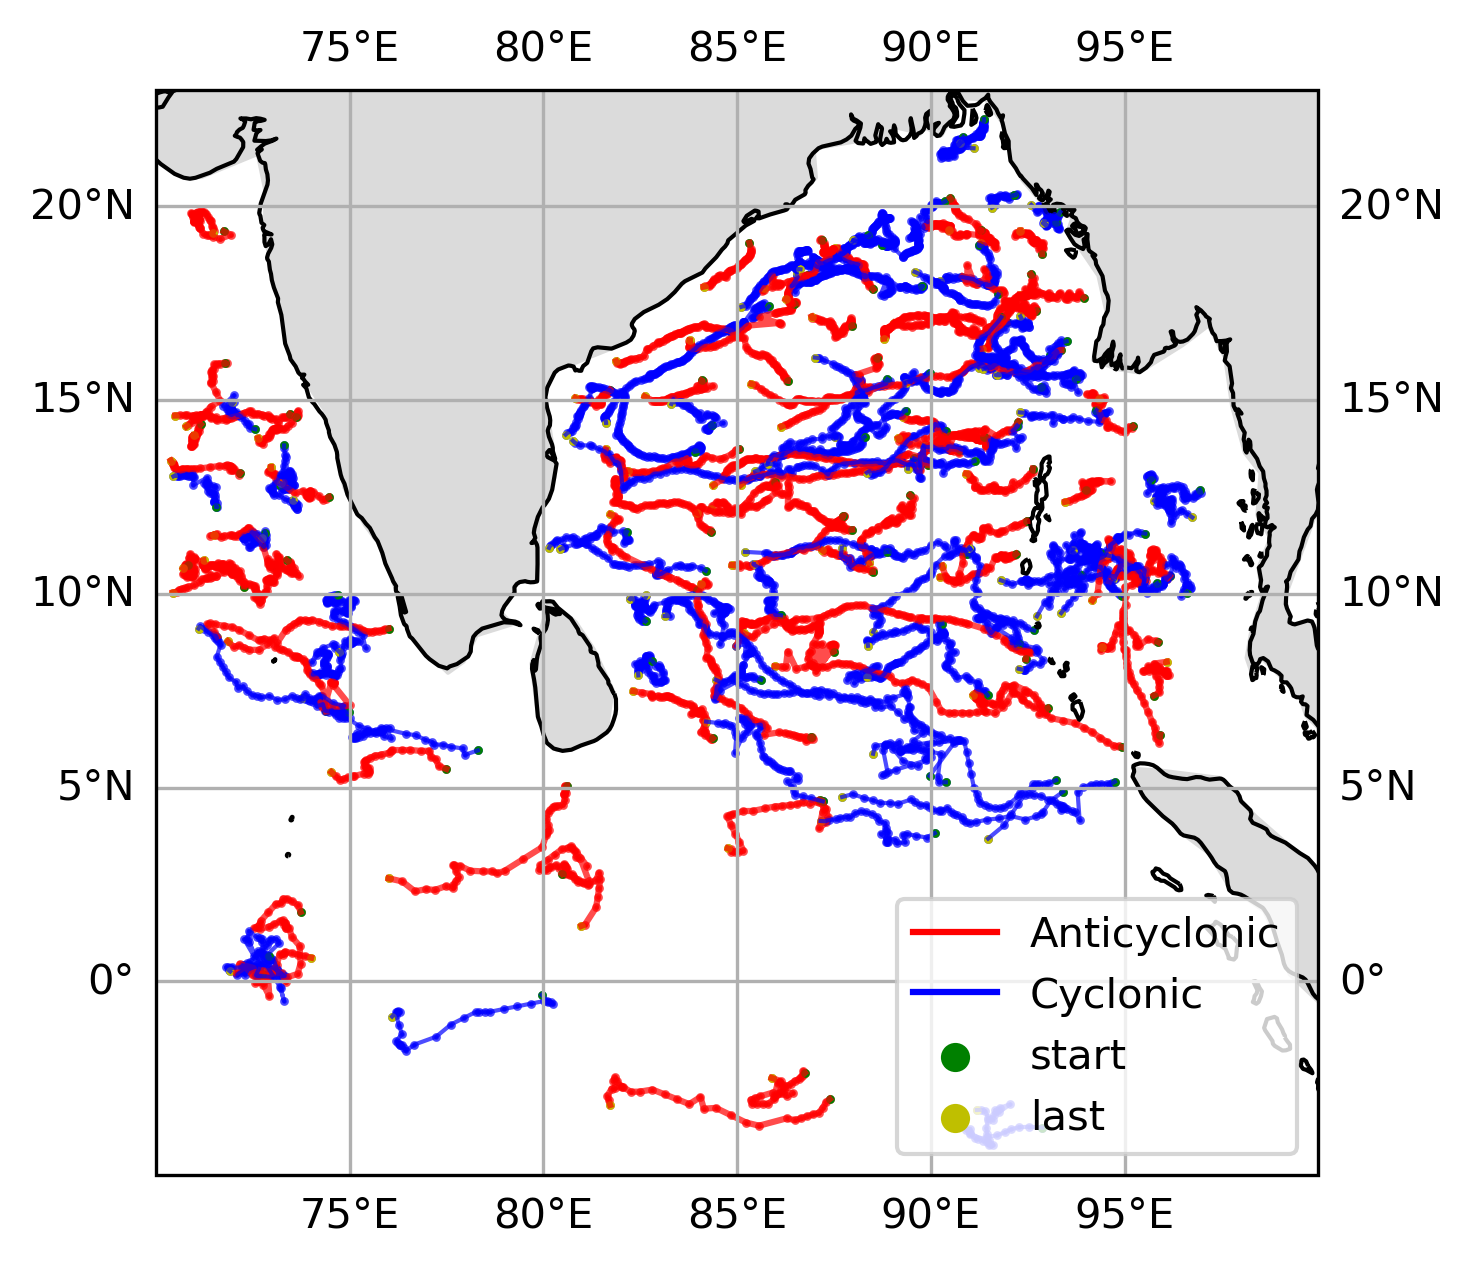

In [ ]:
i=1993
g, axs = plt.subplots(1,1,figsize=(5,5),dpi=300,subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)})
ax = axs
ax.coastlines()
land = cfeature.NaturalEarthFeature('physical', 'land', '110m', edgecolor='face',
                                facecolor=cfeature.COLORS['land_alt1'])
ax.add_feature(land, zorder=0)
ax.set_aspect("equal")
timeind=ac_time.year==i
trackind=np.unique(ac_track[timeind])
plt.plot(0,0,'r',label='Anticyclonic')
plt.plot(0,0,'b',label='Cyclonic')
plt.scatter(0,0,c='g',label='start')
plt.scatter(0,0,c='y',label='last')
plt.legend()
for j in trackind:
    if np.sum(ac_track==j)<=30:
        continue
    plt.plot(a_x[ac_track==j],a_y[ac_track==j],c='r',linewidth=1.5,alpha=0.7)
    plt.scatter(a_x[ac_track==j],a_y[ac_track==j],c='r',s=1.2,alpha=0.7)
    plt.scatter(a_x[ac_track==j][0],a_y[ac_track==j][0],c='g',s=1.2)
    plt.scatter(a_x[ac_track==j][-1],a_y[ac_track==j][-1],c='y',s=1.2)
timeind=cc_time.year==i
trackind=np.unique(cc_track[timeind])
for j in trackind:
    if np.sum(cc_track==j)<=30:
        continue
    plt.plot(c_x[cc_track==j],c_y[cc_track==j],c='b',linewidth=1,alpha=0.7)
    plt.scatter(c_x[cc_track==j],c_y[cc_track==j],c='b',s=1.2,alpha=0.7)
    plt.scatter(c_x[cc_track==j][0],c_y[cc_track==j][0],c='g',s=1.2)
    plt.scatter(c_x[cc_track==j][-1],c_y[cc_track==j][-1],c='y',s=1.2)
ax.set_xlim(70,100)
ax.set_ylim(-5,23)
ax.gridlines(draw_labels=True)
plt.savefig(f'draws/track_{i}.png')